<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%EB%AC%B8%EC%84%9C%EC%9C%A0%EC%82%AC%EB%8F%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [2]:
def cos_similarity(v1,v2):
  dot_product=np.dot(v1,v2)
  l2_norm=(np.sqrt(sum(np.square(v1)))) * np.sqrt(sum(np.square(v2)))
  similarity=dot_product / l2_norm

  return similarity

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

doc_li = ['if you take the blue pill,the story ends',
            'if you take the red pill,you stay in Wonderland',
            'if you take the red pill, I show you how deep the rabbit hole goes']

tfidf_vect_simple=TfidfVectorizer()
feature_vect_simple=tfidf_vect_simple.fit_transform(doc_li)
print(feature_vect_simple.shape)

(3, 18)


변환된 행렬은 희소 행렬임

In [4]:
# TFidfVectorizer로 transform()한 결과는 희소 행렬이므로 밀집 행렬로 변환
feature_vect_dense=feature_vect_simple.todense()

# 첫 번째 문장과 두 번쨰 문장의 피처 벡터 추출
vect1=np.array(feature_vect_dense[0]).reshape(-1,)
vect2=np.array(feature_vect_dense[1]).reshape(-1,)

# 첫 번쨰 문장과 두 번째 문장의 피처 벡터로 두 개 문장의 코사인 유사도 추출
similarity_simple=cos_similarity(vect1,vect2)
print(f'문장1, 문장 2 cosine 유사도:{format(similarity_simple)}')

문장1, 문장 2 cosine 유사도:0.40207758214950134


In [5]:
# 첫 번째 문장과 두 번쨰 문장의 피처 벡터 추출
vect1=np.array(feature_vect_dense[0]).reshape(-1,)
vect3=np.array(feature_vect_dense[2]).reshape(-1,)

# 첫 번쨰 문장과 두 번째 문장의 피처 벡터로 두 개 문장의 코사인 유사도 추출
similarity_simple=cos_similarity(vect1,vect3)
print(f'문장1, 문장 3 cosine 유사도:{format(similarity_simple)}')

vect2=np.array(feature_vect_dense[1]).reshape(-1,)
vect3=np.array(feature_vect_dense[2]).reshape(-1,)

# 첫 번쨰 문장과 두 번째 문장의 피처 벡터로 두 개 문장의 코사인 유사도 추출
similarity_simple=cos_similarity(vect2,vect3)
print(f'문장2, 문장 3 cosine 유사도:{format(similarity_simple)}')

문장1, 문장 3 cosine 유사도:0.40425044775948626
문장2, 문장 3 cosine 유사도:0.45647296026166395


In [6]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_simple_pair=cosine_similarity(feature_vect_simple[0],feature_vect_simple)
print(similarity_simple_pair)

[[1.         0.40207758 0.40425045]]


In [7]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_simple_pair=cosine_similarity(feature_vect_simple[0],feature_vect_simple[1:])
print(similarity_simple_pair)

[[0.40207758 0.40425045]]


### Opinion Review  데이터 세트를 이용한 문서 유사도 측정


In [8]:
import zipfile
import os

zip_path = '/content/opinosis+opinion+frasl+review.zip'
extract_path = 'topics'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    for file in zip_ref.namelist():
        if '/topics' in file:
            zip_ref.extract(file, extract_path)

In [10]:
# nltk 데이터 다운
import nltk

nltk.download('punkt_tab')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [14]:
from nltk.stem import WordNetLemmatizer
import nltk
import string

# string.punctuation는 영어 구두점들을 가져옵니다.(예:!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~)
# ord() : 문자 하나를 해당 문자의 유니코드(Unicode)정수값으로 변환
# 문장부호 각각을 유니코드 정수값으로 변환하고, 그 값을 key로 하는 dictionary 만듦
remove_punct_dict = dict((ord(punct),None)for punct in string.punctuation)
lemmar=WordNetLemmatizer()

# 입력으로 들어온 token단어들에 대해서 lemmatization 어근 변환
def LemTokens(tokens):
  return [lemmar.lemmatize(token)for token in tokens]

# TfidfVectorizer 객체 생성 시 tokenizer 인자로 해당 함수를 설정하여 lemmatization 적용
# 입력으로 문장을 받아서 stop words 제거 -> 소문자 변환 -> 단어 토큰화 -> lemmatization 어근 변환
def LemNormalize(text):
  return LemTokens(nltk.word_tokenize(text.lower().translate(remove_punct_dict)))

In [23]:
import glob
import os
from nltk.stem import WordNetLemmatizer
from sklearn.cluster import KMeans

# 여러 개의 파일을 DataFrame으로 로딩
path = '/content/topics/OpinosisDataset1.0/topics'

# 모든 .data 파일들의 파일명을 리스트로 취합
all_files = glob.glob(os.path.join(path, "*.data"))

filename_li = []
opinion_text = []

# 개별 파일들의 파일명과 파일 내용을 리스트로 취합
for file_ in all_files:

    # 개별 파일을 읽어서 DataFrame으로 생성
    df = pd.read_table(
        file_,
        index_col=None,
        header=0,
        encoding='latin1'
    )

    # 파일 경로에서 실제 파일명만 추출
    filename = os.path.basename(file_)

    # 파일명 리스트와 파일 내용 리스트에 추가
    filename_li.append(filename)
    opinion_text.append(df.to_string())

# 파일명 리스트와 파일 내용 리스트를 DataFrame으로 생성
document_df = pd.DataFrame({
    'filename': filename_li,
    'opinion_text': opinion_text
})

tfidf_vect = TfidfVectorizer(
    tokenizer=LemNormalize,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=0.05,
    max_df=0.85
)

feature_vect = tfidf_vect.fit_transform(
    document_df['opinion_text']
)

km_cluster = KMeans(
    n_clusters=3,
    max_iter=1000,
    random_state=0
)

km_cluster.fit(feature_vect)

cluster_label = km_cluster.labels_
cluster_centers = km_cluster.cluster_centers_

document_df['cluster_label'] = cluster_label

호텔을 주제로 군집화된 문서를 이용해 특정 문서와 다른 문서 간의 유사도 알아보기

문서를 피처 벡터화해 변환하면 문서 내 단어(Word)에 출현 빈도와 같은 값을 부여해 각 문서가 단어 피처의 값으로 벡터화됩니다.

In [24]:
from sklearn.metrics.pairwise import cosine_similarity

# cluster_label=2인 데이터는 호텔로 군집화된 데이터임. DataFrame에서 해당 인덱스를 추출
hotel_indexes=document_df[document_df['cluster_label']==2].index
print(f'호텔로 클러스터링 된 문서들의 DataFrame Index:{hotel_indexes}')

# 호텔로 군집화된 데이터 중 첫 번째 문서를 추출해 파일명 표시
comparison_docname=document_df.iloc[hotel_indexes[0]]['filename']
print(f'#### 비교 기준 문서명 {comparison_docname} 와 타 문서 유사도 ####')

# document_df에서 추출한 Index 객체를 feature_vect를 입력해 호텔 군집화된 feature_vect 추출
#이를 이용해 호텔로 군집화된 문서 중 첫 번쨰 문서와 다른 문서 간의 코사인 유사도 측정.```
similarity_pair=cosine_similarity(feature_vect[hotel_indexes[0]],feature_vect[hotel_indexes])
print(similarity_pair)

호텔로 클러스터링 된 문서들의 DataFrame Index:Index([5, 6, 7, 10, 11, 14, 18, 19, 21, 23, 24, 26, 31, 34, 42, 43, 46, 48,
       49],
      dtype='int64')
#### 비교 기준 문서명 voice_garmin_nuvi_255W_gps.txt.data 와 타 문서 유사도 ####
[[1.         0.0781002  0.034098   0.1016839  0.07862675 0.02354433
  0.07586943 0.28499816 0.03707414 0.04163594 0.0448389  0.02967881
  0.0392295  0.01300141 0.0530008  0.27548539 0.01822013 0.01718641
  0.12148737]]


가장 유사도가 큰 파일명 및 유사도:filename      directions_garmin_nuvi_255W_gps.txt.data
similarity                                    0.284998
Name: 19, dtype: object


Text(0.5, 1.0, 'voice_garmin_nuvi_255W_gps.txt.data')

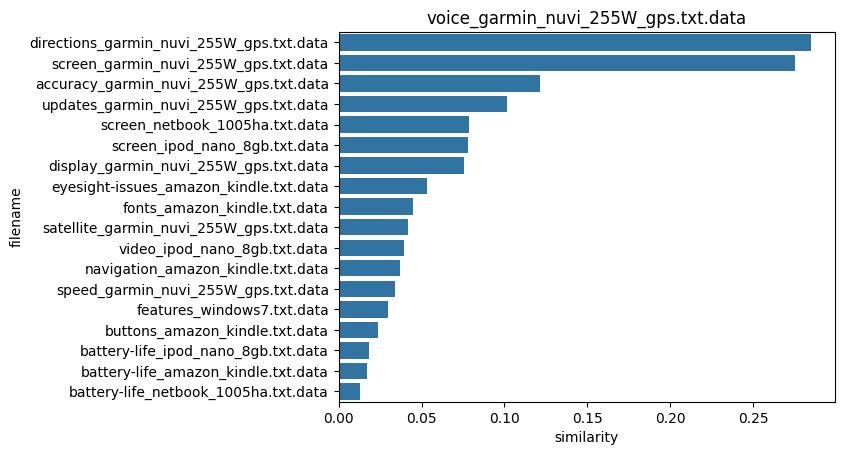

In [25]:
# 첫 번째 문서와 타 문서간 유사도가 큰 순으로 정렬한 인덱스 추출하되 자기 자신을 제외
sorted_index=similarity_pair.argsort()[:,::-1]
sorted_index=sorted_index[:,1:]

# 유사도가 큰 순으로 hotel_indexes를 추출하여 재정렬
hotel_sorted_indexes = hotel_indexes[sorted_index.reshape(-1)]

# 유사도가 큰 순으로 유사도 값을 재정렬하되 자기 자신은 제외
hotel_1_sim_value=np.sort(similarity_pair.reshape(-1))[::-1]
hotel_1_sim_value=hotel_1_sim_value[1:]

# 유사도가 큰 순으로 정렬된 인덱스와 유사도 값을 이용해 파일명과 유사도값을 막대 그래프로 시각화
hotel_1_sim_df=pd.DataFrame()
hotel_1_sim_df['filename']=document_df.iloc[hotel_sorted_indexes]['filename']
hotel_1_sim_df['similarity']=hotel_1_sim_value
print(f'가장 유사도가 큰 파일명 및 유사도:{hotel_1_sim_df.iloc[0,:]}')

sns.barplot(x='similarity',y='filename',data=hotel_1_sim_df)
plt.title(comparison_docname)

첫 번쨰 문서인 GPS 내비게이션에 대한 사용자 리뷰들을 모아놓은 데이터인 accuracy_garmin_nuvi_255W_gps와 가장 비슷한 문서는 directions_garmin_nuvi_255_gps.txt 입니다.

